# Session 9: A route planner instead of a fixed route set

**Question:** how much better can a route get if the planner may choose any path through the airspace, rather than one of the 45 fixed routes used so far?

**Builds on:** Sessions 3–8 chose among a fixed family of routes (5 lateral bends × 9 flight levels). Session 8 found that on about a third of nights none of them was safe against every vertical error, which raises the question of whether a better route existed outside the family.

**Approach:**
1. Divide the route into 60 stages (~30 km). At each stage boundary the aircraft can be at 25 lateral offsets (−300 to +300 km, every 25 km) and 9 flight levels (FL310–FL390); between stages it may move one offset step and one flight level.
2. Cost of each step: fuel per km at that level (from the Session 8 fuel table for that night and mass), plus the fuel to climb (m·g·Δh at an assumed 30% efficiency, about 15 kg per 1,000 ft at 64 t; descents cost nothing extra), plus λ × the distance flown in persistent-contrail (PCR) conditions, judged at 3 points along each step (every ~10 km) with the altitude following any climb or descent.
3. Find the cheapest path by dynamic programming over the stages: exact on this grid, and checked against brute force over every possible path on small grids (automated tests). Sideways steps lengthen the path, so the aircraft arrives later than great-circle timing; the planner re-evaluates the weather with its planned path's delay and re-plans until the path repeats.
4. Check the planner's cost model against the full pipeline, then re-fly every planned path through the pipeline (`evaluate_route` and the fuel model) and compare it with the best fixed route.

**Assumptions:** as Session 8 (A320, 230 m/s, no wind, cruise only, ERA5 on 10 levels, no humidity scaling, the same 24 nights). All grid points at one stage share the delay of the last planned path. Deterministic weather only; robustness to vertical errors is Session 11.

**Version note:** a first version timed every stage by great-circle progress and judged each step only at its start. Re-flown, its paths had up to 308 km more contrail distance than it estimated; the diagnosis and fix are under *Corrections* in the results.

**Sections:** 1. Setup · 2. One night's cost model · 3. Checks against the pipeline · 4. Planning one night · 5. All 24 nights · 6. Figures · Results

## 1. Setup

Fuel rates per flight level come from the Session 8 fuel table (great-circle route, each night and mass); a level outside the flight envelope for a mass is not flyable.

In [1]:
import sys, gc, time, warnings
from dataclasses import replace
from pathlib import Path
SRC = (Path("..") / "src").resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from contrail_routing import config
from contrail_routing.met import load_era5_checked, load_region
from contrail_routing.geometry import flight_from_path, flight_level_to_m, haversine_km
from contrail_routing.evaluate import evaluate_route, evaluate_routes
from contrail_routing.performance import fuel_burn
from contrail_routing.planner import (build_cost_model, plan_timed, pcr_at_points,
                                      fixed_route_estimate, climb_kg_per_level)

warnings.filterwarnings("ignore", message=r"\s*Met data appears to have originated from ECMWF")
pd.set_option("display.width", 220)

results_dir = Path("..") / "results"
fig_dir = results_dir / "figures"
s8_dir = results_dir / "session8"
s9_dir = results_dir / "session9"
s9_dir.mkdir(parents=True, exist_ok=True)

DATES = config.STUDY_DATES
N_STAGES = 60
OFFSETS_KM = np.arange(-300, 301, 25)
FLIGHT_LEVELS = np.array(config.FLIGHT_LEVELS + [390])
MASSES = {"light_56t": 56000.0, "model_default": None,
          "heavy_68t": 68000.0, "very_heavy_72t": 72000.0}
LAMBDAS = [0.1, 1.0, 10.0]
VARIANTS = {"constant_level": 0, "free_level": 1}    # max flight-level change per stage
GC_KM = float(haversine_km(*config.ORIGIN, *config.DESTINATION))

fuel8 = pd.read_csv(s8_dir / "fuel_by_night.csv")
pcr8 = pd.read_csv(s8_dir / "pcr_base_by_night.csv", index_col="route")
specs = config.route_specs(flight_levels=list(FLIGHT_LEVELS))

def fuel_rates(date, mass_case):
    """kg/km per flight level (inf if outside the envelope) and the start mass, from the great circle."""
    g = fuel8[(fuel8["date"] == date) & (fuel8["mass_case"] == mass_case)].set_index("route")
    gc_rows = g.loc[[f"GC0_FL{fl}" for fl in FLIGHT_LEVELS]]
    rate = np.where(gc_rows["feasible"], gc_rows["fuel_kg"] / GC_KM, np.inf)
    mass = float(gc_rows.loc[gc_rows["feasible"], "start_mass_kg"].mean())
    return rate, mass

print(f"Grid: {N_STAGES + 1} stage boundaries x {len(OFFSETS_KM)} offsets x {len(FLIGHT_LEVELS)} levels "
      f"= {(N_STAGES + 1) * len(OFFSETS_KM) * len(FLIGHT_LEVELS):,} points; stage length {GC_KM / N_STAGES:.1f} km")
print(f"Climb fuel per 1,000 ft at 64 t: {climb_kg_per_level(64000.0):.1f} kg")

Grid: 61 stage boundaries x 25 offsets x 9 levels = 13,725 points; stage length 30.0 km
Climb fuel per 1,000 ft at 64 t: 14.8 kg


## 2. One night's cost model

ERA5 is loaded and checked as in Session 8, then PCR is evaluated along every possible step of the grid (3 points per step) with the same pycontrails model the pipeline uses. This first model uses great-circle timing; each plan then re-times it along its own path.

In [2]:
def load_night(date):
    met, _ = load_era5_checked((f"{date}T00", f"{date}T06"), config.LEVELS_FINE,
                               config.REGION_LON, config.REGION_LAT)
    region = load_region(met, config.REGION_LON, config.REGION_LAT)
    met.data.close()
    return region

def model_for(date, region, rate, climb_kg, delay_s=None):
    return build_cost_model(region, config.ORIGIN, config.DESTINATION, pd.Timestamp(f"{date} 00:00"),
                            config.CRUISE_SPEED_MS, N_STAGES, OFFSETS_KM, FLIGHT_LEVELS,
                            rate, climb_kg, delay_s=delay_s)

def night_model(date, region):
    rate, mass = fuel_rates(date, "model_default")
    return model_for(date, region, rate, climb_kg_per_level(mass))

DATE0 = "2022-03-01"
region0 = load_night(DATE0)
cm0 = night_model(DATE0, region0)
level_share = cm0.pcr_frac[:, :, cm0.max_dj, :, cm0.max_dk].mean(axis=(0, 1))   # straight-and-level steps
print("Share of straight-and-level steps in PCR conditions, by flight level:")
print(pd.Series(level_share.round(3), index=[f"FL{fl}" for fl in FLIGHT_LEVELS]).to_string())

ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
Share of straight-and-level steps in PCR conditions, by flight level:
FL310    0.596
FL320    0.419
FL330    0.504
FL340    0.355
FL350    0.344
FL360    0.227
FL370    0.102
FL380    0.000
FL390    0.000


## 3. Checks against the pipeline

**A.** The planner evaluates PCR at arbitrary points; at the points of the 45 fixed routes it must give exactly the pipeline's PCR.

**B.** The planner's cost model (3 points per ~30 km stage, timed along the route, fuel per km from the great circle) is applied to the 45 fixed routes and compared with the pipeline's results for the same routes (Session 8). This measures the model's own error before any planning.

In [3]:
routes0 = config.build_routes(specs, departure=pd.Timestamp(f"{DATE0} 00:00"))
tables0 = evaluate_routes(routes0, region0)
all_pts = pd.concat(tables0.values(), ignore_index=True)
pcr_pts = pcr_at_points(region0, all_pts["longitude"], all_pts["latitude"], all_pts["altitude_m"],
                        all_pts["time"].to_numpy())
n_diff = int((pcr_pts != all_pts["PCR"].to_numpy()).sum())
print(f"Check A: {len(all_pts):,} points, PCR differs at {n_diff}")
assert n_diff == 0
print("The planner's PCR evaluation is identical to the pipeline's.")

def fixed_route_check(date, region):
    rate, _ = fuel_rates(date, "model_default")
    f8 = fuel8[(fuel8["date"] == date) & (fuel8["mass_case"] == "model_default")].set_index("route")
    rows = []
    for name, s in specs.items():
        k = int(np.flatnonzero(FLIGHT_LEVELS == s["flight_level"])[0])
        est = fixed_route_estimate(region, config.ORIGIN, config.DESTINATION, pd.Timestamp(f"{date} 00:00"),
                                   config.CRUISE_SPEED_MS, N_STAGES, s["offset_km"], s["flight_level"], rate[k])
        rows.append({"date": date, "route": name, "pcr_est_km": est["pcr_km"], "pcr_pipeline_km": pcr8.at[name, date],
                     "fuel_est_kg": est["fuel_kg"], "fuel_pipeline_kg": f8.at[name, "fuel_kg"]})
    return pd.DataFrame(rows)

chk0 = fixed_route_check(DATE0, region0)
chk0["pcr_err_km"] = chk0["pcr_est_km"] - chk0["pcr_pipeline_km"]
chk0["fuel_err_pct"] = 100 * (chk0["fuel_est_kg"] / chk0["fuel_pipeline_kg"] - 1)
print(f"\nCheck B ({DATE0}, 45 fixed routes, model-estimate mass):")
print(chk0[["pcr_err_km", "fuel_err_pct"]].describe().loc[["mean", "min", "50%", "max"]].round(2).to_string())
print("\nLargest PCR differences:")
print(chk0.reindex(chk0["pcr_err_km"].abs().sort_values(ascending=False).index)
      .head(5)[["route", "pcr_est_km", "pcr_pipeline_km", "fuel_err_pct"]].round(1).to_string(index=False))

Evaluated 45 routes, no missing values.
Check A: 6,120 points, PCR differs at 0
The planner's PCR evaluation is identical to the pipeline's.

Check B (2022-03-01, 45 fixed routes, model-estimate mass):
      pcr_err_km  fuel_err_pct
mean       -2.03         -0.08
min       -20.19         -0.54
50%        -0.30         -0.02
max        17.69          0.14

Largest PCR differences:
      route  pcr_est_km  pcr_pipeline_km  fuel_err_pct
NW300_FL340       255.8            276.0          -0.1
  GC0_FL330      1500.1           1518.0          -0.0
SE300_FL370       431.7            414.0          -0.4
NW300_FL320       549.7            565.8          -0.2
SE150_FL320      1076.1           1090.2          -0.0


## 4. Planning one night

For each mass and λ, two planners: one that holds a single flight level (chosen freely) and one that may change level between stages. Each planned path is re-flown through the full pipeline, and compared with the best of the 45 fixed routes for the same mass and λ (pipeline values from Session 8). Gain = J of the best fixed route − J of the re-flown planned path, in kg of fuel-equivalent; positive means the planner found something better.

In [4]:
def refly(p, date, region, mass_kg, name):
    """Fly a planned path through the full pipeline: PCR km, fuel and envelope check."""
    fl = flight_from_path(p["lon"], p["lat"], flight_level_to_m(p["flight_level"].astype(float)),
                          pd.Timestamp(f"{date} 00:00"), config.CRUISE_SPEED_MS, name=name)
    track = evaluate_route(fl, region)
    fb = fuel_burn(track, config.AIRCRAFT, config.CRUISE_SPEED_MS, takeoff_mass_kg=mass_kg)
    return {"pcr_pipe_km": float(track.loc[track["PCR"] > 0, "leg_km"].sum()),
            "fuel_pipe_kg": fb["fuel_kg"], "within_envelope": fb["within_envelope"],
            "length_pipe_km": float(track["leg_km"].sum())}

def best_fixed(date, mass_case, lam):
    f = fuel8[(fuel8["date"] == date) & (fuel8["mass_case"] == mass_case) & fuel8["feasible"]].set_index("route")
    J = f["fuel_kg"] + lam * pcr8.loc[f.index, date]
    r = J.idxmin()
    return r, float(f.at[r, "fuel_kg"]), float(pcr8.at[r, date]), float(J[r])

def plan_night(date, region, cm):
    rows, paths = [], []
    for mc, mass in MASSES.items():
        rate, m_est = fuel_rates(date, mc)
        climb = climb_kg_per_level(mass or m_est)
        cm_m = replace(cm, fuel_per_km=rate, climb_kg=climb)
        rebuild = lambda delay: model_for(date, region, rate, climb, delay)
        for lam in LAMBDAS:
            fr, ff, fp, fJ = best_fixed(date, mc, lam)
            for variant, max_dk in VARIANTS.items():
                p = plan_timed(rebuild, cm_m, lam, config.CRUISE_SPEED_MS, max_dk=max_dk)
                r = refly(p, date, region, mass, f"{date}_{mc}_{lam}_{variant}")
                rows.append({"date": date, "mass_case": mc, "lambda": lam, "variant": variant,
                             "fuel_est_kg": p["fuel_kg"], "pcr_est_km": p["pcr_km"], **r,
                             "level_changes": p["level_changes"], "iterations": p["iterations"],
                             "converged": p["converged"],
                             "max_offset_km": float(np.abs(p["offset_km"]).max()),
                             "levels_used": "/".join(map(str, sorted(set(p["flight_level"].tolist())))),
                             "J_pipe": r["fuel_pipe_kg"] + lam * r["pcr_pipe_km"],
                             "best_fixed_route": fr, "fixed_fuel_kg": ff, "fixed_pcr_km": fp, "J_fixed": fJ})
                paths.append(pd.DataFrame({"date": date, "mass_case": mc, "lambda": lam, "variant": variant,
                                           "stage": np.arange(len(p["offset_km"])),
                                           "offset_km": p["offset_km"], "flight_level": p["flight_level"]}))
    out = pd.DataFrame(rows)
    out["gain_kg"] = out["J_fixed"] - out["J_pipe"]
    return out, pd.concat(paths, ignore_index=True)

t0 = time.time()
res0, paths0 = plan_night(DATE0, region0, cm0)
print(f"{DATE0}: {len(res0)} plans in {time.time() - t0:.0f} s\n")
print(res0[["mass_case", "lambda", "variant", "levels_used", "max_offset_km", "fuel_pipe_kg", "pcr_pipe_km",
            "best_fixed_route", "fixed_fuel_kg", "fixed_pcr_km", "gain_kg", "within_envelope"]]
      .round(1).to_string(index=False))

2022-03-01: 24 plans in 12 s

     mass_case  lambda        variant levels_used  max_offset_km  fuel_pipe_kg  pcr_pipe_km best_fixed_route  fixed_fuel_kg  fixed_pcr_km  gain_kg  within_envelope
     light_56t     0.1 constant_level         390            0.0        4387.2          0.0        GC0_FL390         4387.2           0.0      0.0             True
     light_56t     0.1     free_level         390            0.0        4387.2          0.0        GC0_FL390         4387.2           0.0      0.0             True
     light_56t     1.0 constant_level         390            0.0        4387.2          0.0        GC0_FL390         4387.2           0.0      0.0             True
     light_56t     1.0     free_level         390            0.0        4387.2          0.0        GC0_FL390         4387.2           0.0      0.0             True
     light_56t    10.0 constant_level         390            0.0        4387.2          0.0        GC0_FL390         4387.2           0.0      0.0    

## 5. All 24 nights

The same for every night, plus Check B on each night's 45 fixed routes. Roughly 30–90 s per night (each plan re-times the weather along its path).

In [5]:
results, paths, checks = [], [], []
t_start = time.time()
for i, date in enumerate(DATES, 1):
    t0 = time.time()
    region = region0 if date == DATE0 else load_night(date)
    cm = night_model(date, region)
    r, p = plan_night(date, region, cm)
    results.append(r); paths.append(p); checks.append(fixed_route_check(date, region))
    del region, cm
    gc.collect()
    print(f"[{i:2d}/{len(DATES)}] {date} done in {time.time() - t0:3.0f} s | "
          f"median gain {r['gain_kg'].median():6.1f} kg | outside envelope: {int((~r['within_envelope']).sum())}")
print(f"Total {(time.time() - t_start) / 60:.1f} min")

res = pd.concat(results, ignore_index=True)
paths_all = pd.concat(paths, ignore_index=True)
chk = pd.concat(checks, ignore_index=True)
chk["pcr_err_km"] = chk["pcr_est_km"] - chk["pcr_pipeline_km"]
chk["fuel_err_pct"] = 100 * (chk["fuel_est_kg"] / chk["fuel_pipeline_kg"] - 1)
res["pcr_err_km"] = res["pcr_est_km"] - res["pcr_pipe_km"]
res["fuel_err_pct"] = 100 * (res["fuel_est_kg"] / res["fuel_pipe_kg"] - 1)

res.to_csv(s9_dir / "planner_vs_fixed_by_night.csv", index=False)
paths_all.to_csv(s9_dir / "planned_paths.csv", index=False)
chk.to_csv(s9_dir / "cost_model_check_fixed_routes.csv", index=False)

ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 1/24] 2022-01-01 done in  28 s | median gain   52.0 kg | outside envelope: 0
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 2/24] 2022-01-15 done in  17 s | median gain    0.0 kg | outside envelope: 0
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 3/24] 2022-02-01 done in  20 s | median gain    5.6 kg | outside envelope: 0
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 4/24] 2022-02-15 done in  14 s | median gain   -0.0 kg | outside envelope: 0
[ 5/24] 2022-03-01 done in  13 s | median gain    0.0 kg | outside envelope: 0
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 6/24] 2022-03-15 done in  17 s | median gain   -0.0 kg | outside envelope: 0
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 7/24] 2022-04-01 done in  

In [6]:
print("Check B, all nights (1,080 fixed routes): planner estimate minus pipeline")
print(chk[["pcr_err_km", "fuel_err_pct"]].describe().loc[["mean", "min", "50%", "max"]].round(2).to_string())
print(f"Routes with |PCR error| > 50 km: {int((chk['pcr_err_km'].abs() > 50).sum())} of {len(chk)}")

print("\nPlanned paths re-flown through the pipeline: estimate minus pipeline")
print(res[["pcr_err_km", "fuel_err_pct"]].describe().loc[["mean", "min", "50%", "max"]].round(2).to_string())
print("Planned paths outside the flight envelope when re-flown:", int((~res["within_envelope"]).sum()), "of", len(res))
print("Re-timing: plans per number of iterations", res["iterations"].value_counts().sort_index().to_dict(),
      "| not converged after 5:", int((~res["converged"]).sum()))
print("\nLargest PCR underestimates (planned paths):")
print(res.reindex(res["pcr_err_km"].sort_values().index).head(5)[
    ["date", "mass_case", "lambda", "variant", "pcr_est_km", "pcr_pipe_km", "level_changes", "max_offset_km"]]
    .round(1).to_string(index=False))

ok = res[res["within_envelope"]]
summary = (ok.groupby(["variant", "mass_case", "lambda"])["gain_kg"]
           .agg(median="median", mean="mean", min="min", max="max",
                share_positive=lambda g: (g > 0.5).mean()).round(2))
print("\nGain over the best fixed route (kg of fuel-equivalent, pipeline values; > 0 = planner better):")
print(summary.to_string())

print("\nWhere the gain comes from (lambda = 10, model-estimate mass, free level):")
sel = ok[(ok["lambda"] == 10.0) & (ok["mass_case"] == "model_default") & (ok["variant"] == "free_level")]
print(pd.DataFrame({"fuel_change_kg": (sel["fuel_pipe_kg"] - sel["fixed_fuel_kg"]).describe(),
                    "pcr_change_km": (sel["pcr_pipe_km"] - sel["fixed_pcr_km"]).describe()})
      .loc[["mean", "min", "50%", "max"]].round(1).to_string())
print("Nights where the planned path has less PCR than the best fixed route:",
      int((sel["pcr_pipe_km"] < sel["fixed_pcr_km"] - 0.5).sum()), "of", len(sel),
      "| reaches zero PCR when the best fixed route does not:",
      int(((sel["pcr_pipe_km"] == 0) & (sel["fixed_pcr_km"] > 0)).sum()))
summary.to_csv(s9_dir / "gain_summary.csv")

Check B, all nights (1,080 fixed routes): planner estimate minus pipeline
      pcr_err_km  fuel_err_pct
mean       -0.08         -0.11
min       -35.99         -0.60
50%         0.00         -0.07
max        30.84          0.14
Routes with |PCR error| > 50 km: 0 of 1080

Planned paths re-flown through the pipeline: estimate minus pipeline
      pcr_err_km  fuel_err_pct
mean       -0.79          0.11
min       -69.82         -0.31
50%         0.00          0.00
max        14.33          2.10
Planned paths outside the flight envelope when re-flown: 0 of 576
Re-timing: plans per number of iterations {2: 554, 3: 13, 4: 2, 5: 7} | not converged after 5: 7

Largest PCR underestimates (planned paths):
      date     mass_case  lambda        variant  pcr_est_km  pcr_pipe_km  level_changes  max_offset_km
2022-01-01     light_56t     1.0     free_level       329.1        398.9             11           50.0
2022-01-01     light_56t     1.0 constant_level       395.1        459.2              0  

## 6. Figures

Left: planned paths on the night with the largest gain (model-estimate mass, λ = 10), with the fixed-route family for reference. Right: gain over the best fixed route on every night, by mass, for the free-level planner at λ = 10.

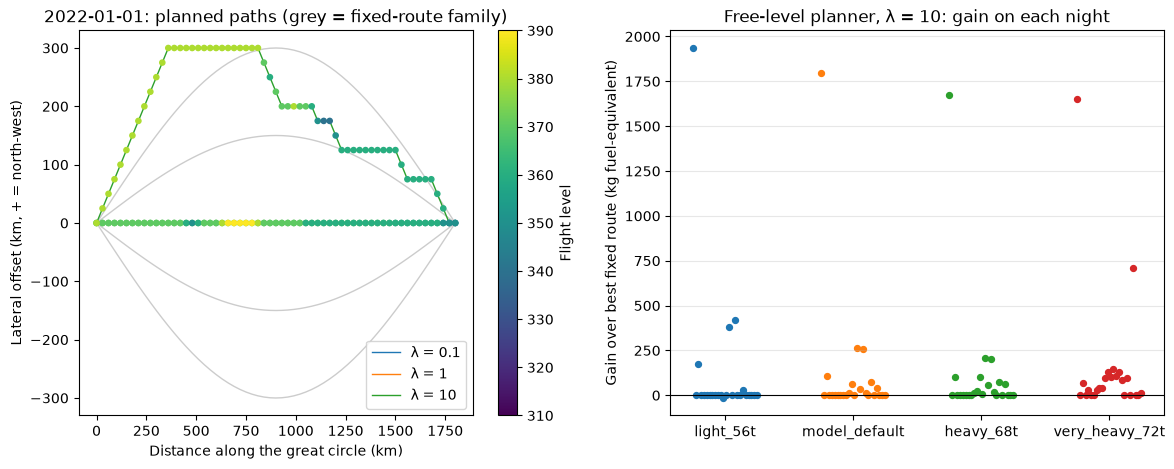

In [7]:
sel = res[(res["mass_case"] == "model_default") & (res["lambda"] == 10.0) & (res["variant"] == "free_level")]
date_x = sel.loc[sel["gain_kg"].idxmax(), "date"]
px = paths_all[(paths_all["date"] == date_x) & (paths_all["mass_case"] == "model_default")
               & (paths_all["variant"] == "free_level")]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
frac = np.linspace(0, 1, N_STAGES + 1)
dist = frac * GC_KM
for a in [-300, -150, 0, 150, 300]:
    ax.plot(dist, a * np.sin(np.pi * frac), color="0.8", lw=1, zorder=1)
for lam, g in px.groupby("lambda"):
    sc = ax.scatter(dist, g["offset_km"], c=g["flight_level"], cmap="viridis", vmin=310, vmax=390, s=14, zorder=3)
    ax.plot(dist, g["offset_km"], lw=1, label=f"λ = {lam:g}", zorder=2)
ax.set_xlabel("Distance along the great circle (km)")
ax.set_ylabel("Lateral offset (km, + = north-west)")
ax.set_title(f"{date_x}: planned paths (grey = fixed-route family)")
ax.legend(loc="lower right")
fig.colorbar(sc, ax=ax, label="Flight level")

ax = axes[1]
ok10 = res[(res["lambda"] == 10.0) & (res["variant"] == "free_level") & res["within_envelope"]]
for k, mc in enumerate(MASSES):
    v = ok10.loc[ok10["mass_case"] == mc, "gain_kg"].values
    ax.scatter(np.full(len(v), k) + np.linspace(-0.25, 0.25, len(v)), v, s=18)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(MASSES)))
ax.set_xticklabels(list(MASSES))
ax.set_ylabel("Gain over best fixed route (kg fuel-equivalent)")
ax.set_title("Free-level planner, λ = 10: gain on each night")
ax.grid(alpha=0.3, axis="y")
fig.savefig(fig_dir / "session9_planner.png", dpi=150, bbox_inches="tight")
plt.show()

## Results

### Setup

A route planner over a grid of 61 stage boundaries (~30 km apart) × 25 lateral offsets (−300 to +300 km) × 9 flight levels (FL310–FL390), with at most one offset step and one level change per stage, compared with the best of the 45 fixed routes on the 24 nights of Session 8. Four start-of-cruise masses (56 t, model estimate ≈64 t, 68 t, 72 t), λ = 0.1, 1 and 10 kg/km, and two planners: one holding a single (freely chosen) flight level, one free to change level. Fuel per km for each level comes from the Session 8 great-circle results for that night and mass; a climb costs m·g·Δh at 30% efficiency (≈15 kg per 1,000 ft at 64 t); descents cost nothing extra. Every planned path was re-flown through the full pipeline, and all comparisons use the re-flown values.

### Checks

- The planner's contrail evaluation is identical to the pipeline's at all 6,120 points of the 45 fixed routes (2022-03-01).
- The search matches brute force over every possible path on 24 small random grids, and the backtracked path costs exactly what the search found (automated tests; 51 tests pass).
- Where the planner chose the same route as the best fixed route, the re-flown fuel and contrail distance matched to the kilogram (gain 0.0 on every such case on 2022-03-01).
- Cost model on the 45 fixed routes, all 24 nights (1,080 routes): contrail distance within −36 to +31 km of the pipeline (median 0; none off by more than 50 km); fuel within −0.60 to +0.14%.
- Planned paths re-flown (576): contrail distance within −70 to +14 km of the planner's estimate (mean −0.8 km); fuel within −0.31 to +2.10%; none outside the flight envelope.
- Re-timing converged after 2 plans in 554 of 576 cases, 3–4 in 15; 7 did not converge within 5 plans (the last plan was used and re-flown like the others).

### Findings

#### Gain over the best fixed route

Gain = J of the best fixed route − J of the re-flown planned path (kg of fuel-equivalent; positive = planner better), over 24 nights:

| Planner | λ | Mass | Median | Mean | Max | Min | Nights better |
|---|---|---|---|---|---|---|---|
| Constant level | 1 | all four | 0 | −7.8 to −0.1 | 31.7–36.9 | −47.5 to −100.2 | 8–12% |
| Constant level | 10 | all four | 0 | 16.7–40.6 | 266–673 | −100 to −181 | 17% |
| Free level | 1 | 56 t / ≈64 t / 68 t / 72 t | 0 / 0 / 2.8 / 39.7 | 16.3 / 26.4 / 33.3 / 48.1 | 129–179 | −84.2 to 0 | 21% / 42% / 50% / 67% |
| Free level | 10 | 56 t / ≈64 t / 68 t / 72 t | 0 / 0 / 2.8 / 39.7 | 122.0 / 110.6 / 105.8 / 145.0 | 1,654–1,936 | −15.2 to 0 | 21% / 42% / 50% / 67% |

- **On most nights the planner finds nothing better than the fixed family** (median gain 0 at every mass except 68 t and 72 t with free levels).
- **Changing level helps heavier aircraft.** The free-level planner starts lower and climbs as fuel burns ("step climbs"): for 72 t the median gain is 39.7 kg at λ = 1 and 10.4 kg even at λ = 0.1. On 2022-03-01 it found a contrail-free FL350 → FL360 → FL370 path for 72 t, 32 kg cheaper than the best fixed route.
- **Sideways freedom alone rarely helps:** the constant-level planner beats the fixed family on at most 17% of nights, and loses up to 181 kg on others through the remaining errors in its estimate.
- **Large gains come from a few nights.** At the model-estimate mass and λ = 10, the planned path has less contrail distance than the best fixed route on only 2 of 24 nights (by up to 193 km), and never reaches zero where the fixed family could not. The largest gain (1,799 kg fuel-equivalent) is on 2022-01-01, a night with moist air at every level, where the planned path detours 300 km north-west, the edge of the grid.

### Interpretation

For this flight, the fixed route family was already close to optimal on most nights, because contrail avoidance here is mainly vertical and the family includes every flight level. A planner adds value in two ways: step climbs for heavy aircraft (tens of kg) and, on rare nights, long detours that no fixed route reached. Its main risk is that a search optimising against its own cost model is drawn to the edges of moist regions, where that model is least accurate; re-flying every planned path through the full pipeline is therefore essential, and was what exposed the first version's errors.

### Corrections

- **Planner timing and sampling (first version).** The first version timed every stage by great-circle progress and judged each step only at its start. Its sideways steps are diagonal (25 km across per 30 km along, ~39 km flown), so a path reaching 300 km out arrives up to ~16 min later than assumed. Re-flown, its paths had up to 308 km more contrail distance than estimated, and it lost up to 1,087 kg against the best fixed route. A four-way re-estimate of the 10 worst cases separated the causes:

| Path (2022-01-01) | Planner estimate | + actual timing | + 3 km sampling | Pipeline |
|---|---|---|---|---|
| 56 t, λ = 10, free level | 90 | 309 | 396 | 399 |
| ≈64 t, λ = 10, free level | 90 | 180 | 263 | 263 |
| 300 km offset, constant level | 168 | 267 | 311 | 305 |
| 72 t, λ = 1, free level | 339 | 369 | 466 | 469 |

  The planner now re-plans with its own path's delay and judges each step at 3 points with the altitude following any climb; the worst underestimate fell from 308 km to 70 km.
- **Re-flown paths at constant speed.** `flight_from_path` first interpolated longitude and latitude in straight lines, which does not give constant speed over long segments; a test caught it, and positions now follow great-circle arcs.
- **Free final descent.** The search could drop a level on the final segment at no cost in its model, which the fuel model would then credit; the level is now held on the final segment (covered by a test).

### Limitations

- The grid allows at most ±300 km and one step per stage; on 2022-01-01 the best path reached that edge.
- All grid points at a stage share one delay (that of the last planned path); 7 of 576 plans did not settle within 5 re-plans.
- Fuel per km at each level is taken from the great circle and does not fall as the aircraft gets lighter; the step-climb benefit appears only when the path is re-flown through the full fuel model. Climb fuel uses an assumed 30% efficiency.
- Deterministic weather only: the planned paths are not yet tested against errors in the weather (Session 11).
- One city pair, 24 nights, cruise only, no wind.